# Project Title: Olist Brazilian E-commerce Business Analysis

Executive Summary
This project provides a comprehensive business analysis of the Olist e-commerce dataset, covering over 96,478 delivered orders and R$ 13.22 million in revenue. The analysis focuses on geographical revenue concentration, product category performance, payment method preferences, and the association between between delivery performance and customer satisfaction. The findings reveal that while São Paulo is the primary revenue driver, smaller markets like Bahia demonstrate higher customer spending per order, suggesting diverse strategic opportunities. Furthermore, the analysis quantifies the severe negative impact of delivery delays on customer ratings, providing actionable data for operational improvement.

Importing the important libraries

In [3]:
import pandas as pd 
import matplotlib.pyplot as plt 

Loading Data

In [4]:
customer_details=pd.read_csv("olist_customers_dataset.csv")
customer_details.sample(10)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
97800,cc36b7e33ac2c31ee7de9e6b77ad5ac4,4681829483318507ed55682649de6571,1219,sao paulo,SP
29480,52d0eb41ffcf119a72e14186f7511ae8,6df955547d063a47782dca6c84ebf5c7,60421,fortaleza,CE
88647,0f626c360cd11bf6a7aab968ba6122c5,19155174f7c66d50d2021547e0ce3f55,13148,paulinia,SP
17858,ad5eaed951a10f80d09e7f473a8fd08e,241f2db376ff53e540d2ed0d10a7e3c0,5046,sao paulo,SP
87011,a6472fafe286c66c40540fa2b3217657,8dff9b4552dd014ec5d661e447fbfc4f,88303,itajai,SC
69911,e311c5cf7650f781ee140f998ebd8ae7,db73a3f1ef7a87b89e1aeec92f2a7e38,88410,atalanta,SC
11496,40d09f4385972836121ca581b33f89d5,f5d32f2ee3d4caec1870de481c276bd8,74620,goiania,GO
33755,31f102bb049b4af90fb8b555e921b6d4,695b1a9949ea23a94dc3ce68267c66ee,28910,cabo frio,RJ
86496,afae0f1fa6b82eaa634f9cf041e73814,393a728a1c9ecd68f0ea0c56a3bc482f,22220,rio de janeiro,RJ
82914,6939ce7cd8ff24edc55abf96d82c48ed,2df143c734a8b238db650fffb3346c33,11500,cubatao,SP


In [5]:
customer_details.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 11.0 MB


In [6]:
order=pd.read_csv("olist_orders_dataset.csv")
order.sample(10)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
30663,ff0b6187cf7193bed62f8974ee957d5f,07fcbc2e9b0e4d8b1f9698560ee91a16,delivered,2018-01-17 22:34:38,2018-01-17 22:50:04,2018-01-19 03:09:56,2018-01-23 19:02:54,2018-02-16 00:00:00
63636,ab010289ce552581dd007c7276d4e276,35cf1d9948d4dedcf1be0461d72a35e7,delivered,2018-05-21 14:39:32,2018-05-21 15:59:09,2018-05-22 14:53:00,2018-06-07 17:23:57,2018-06-14 00:00:00
10318,1a82675c731e609f7adc4c93898a6321,e0e0469747218021e8f9b9a240ebb93e,delivered,2018-01-31 19:20:31,2018-01-31 19:30:47,2018-02-05 19:24:29,2018-02-08 20:58:57,2018-02-22 00:00:00
54659,13832510afc6f94103aec19663dd52cf,45403b2dfeb42b112d8ea3449b5b0b9c,delivered,2018-01-29 16:32:03,2018-01-29 16:53:21,2018-01-30 20:37:06,2018-02-28 15:17:15,2018-02-23 00:00:00
88852,4e569a26328664b975f0fea724647fe9,7c87a3891b2629848f3369eafacf7e0a,delivered,2018-07-20 02:27:56,2018-07-21 04:05:20,2018-07-23 15:04:00,2018-07-24 18:18:42,2018-07-30 00:00:00
14124,b1873e7f1c0220c132db2642ecf2bf1b,389efb68674e38efb4ce37a9b72ca36f,delivered,2018-07-16 18:55:19,2018-07-16 19:10:16,2018-07-18 14:02:00,2018-08-07 11:20:45,2018-08-22 00:00:00
11772,18c7a26dfefa3c4686770ca98c0819fb,7cd5270ebafd25ed42d608a9b2620eda,delivered,2018-02-01 22:36:16,2018-02-01 22:51:44,2018-02-08 18:09:32,2018-02-21 19:49:10,2018-03-02 00:00:00
44922,8bbcf79aa902bcc50716a1d94ea9434a,baa42a72ae81c595ba3e380a837b88b7,delivered,2017-03-27 10:43:16,2017-03-27 10:55:13,2017-03-31 21:53:53,2017-04-07 16:43:49,2017-04-20 00:00:00
8653,6e5fc24bede0e47389f2042dc5f8473f,dbeabfe949d48f1d7e102d7df651ec8e,delivered,2018-04-25 23:43:18,2018-04-25 23:55:15,2018-04-26 14:33:00,2018-05-18 13:04:57,2018-05-28 00:00:00
53456,6fcd48d9bce8191ebd8355decc3e54b8,0a6d6d130bb7aac1135874f5768ae229,delivered,2018-02-27 21:53:52,2018-02-27 22:08:23,2018-03-02 17:13:03,2018-03-21 22:21:50,2018-03-23 00:00:00


In [7]:
order.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


In [8]:
order_items=pd.read_csv("olist_order_items_dataset.csv")
order_items.sample(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
16233,251a3d3baf58424356225283feed770f,1,c68fdf078b3ec0596bbc5c7ac409e458,d2374cbcbb3ca4ab1086534108cc3ab7,2017-07-12 13:45:22,31.90,16.11
60934,8adee5f27ae7551113fc26ce21202576,1,32b2a45c7698faf599ad250c65f6f633,e8b3a3a38279a82f0e5d006d5e5b7d2c,2017-12-04 01:38:44,39.90,17.92
596,01643942766bdec224d5593041f714e6,1,b92421ea3b457d6bb68c49f39d4e97a8,897060da8b9a21f655304d50fd935913,2017-08-10 00:30:20,32.50,15.10
109930,f9d0e3b4c20495f400a845fa3aab20c2,1,423b4247c8b7aebba33787ceb34103ae,31561f325664a8a7aba4c8d0c3a9b3db,2018-06-12 12:12:59,49.90,12.79
63729,91811480f57d846cb6b5b418b549f158,1,6f1b3488c5314b527201978357a8d85f,240b9776d844d37535668549a396af32,2018-08-29 09:31:29,259.99,18.01
10244,177f8b6f0cfd6ef224d0caf1e59d89bd,1,f27aff266ad97e75d4a24c893b2c311e,f62d7bb4a613ec758a03342d46b580b2,2018-06-14 16:29:07,750.00,70.24
2364,055bb586a2d17c7677a6096c56b6e2b0,2,9ed0c78e13f71131885275746cc69687,febab0275244b9a49a623f0bd613ca2f,2018-03-12 03:50:49,73.99,77.54
29569,43389a4c5d1f6f0fff4486c6ae61d4ea,1,20a3c5e7a7b340a10612559c2a03f68c,7142540dd4c91e2237acb7e911c4eba2,2017-12-19 08:19:25,69.90,25.33
82649,bbb7e3b704844468f580cf9f68b0ddd5,1,8123e87dd3112536d2f0856287158c8e,16090f2ca825584b5a147ab24aa30c86,2018-07-13 03:06:05,66.49,8.21
71355,a2c173a8905b6e8f3c6ea83b7d9c6b91,1,68a00c2c89cc59b345242ac379ee4b26,c3867b4666c7d76867627c2f7fb22e21,2017-08-04 07:30:19,115.00,38.36


In [9]:
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB


# State Analysis Section:

In [10]:
df1 = customer_details.merge(order[order['order_status'] == 'delivered'], on="customer_id", how="inner")
print(f"After first join: {df1.shape}")

After first join: (96478, 12)


In [11]:
df2 = df1.merge(order_items, on="order_id", how="inner")
print(f"After second join: {df2.shape}")

After second join: (110197, 18)


In [12]:
revenue_by_state = df2.groupby('customer_state')['price'].sum().reset_index()
revenue_by_state = revenue_by_state.sort_values(by='price', ascending=False)
revenue_by_state

,customer_state,price
25,SP,5067633.16
18,RJ,1759651.13
10,MG,1552481.83
22,RS,728897.47
17,PR,666063.51
23,SC,507012.13
4,BA,493584.14
6,DF,296498.41
8,GO,282836.70
7,ES,268643.45


TOP 10 SATATES WITH THE HIGHEST REVENUE IS :

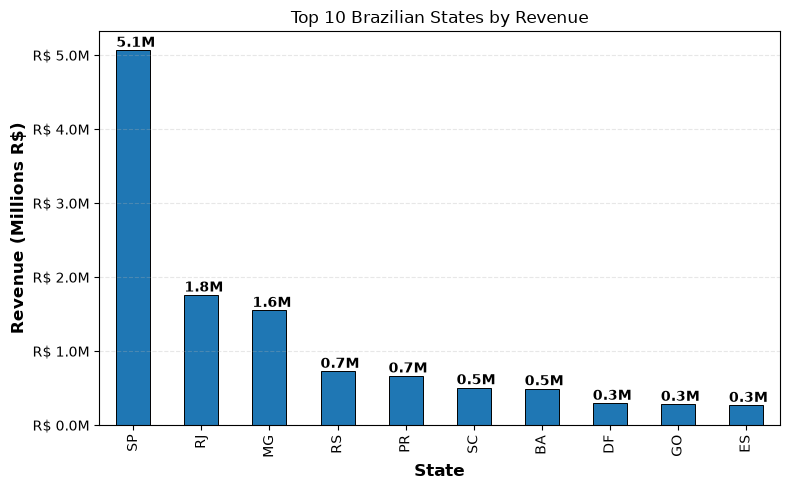

In [13]:
revenue_by_state.head(10).plot(kind='bar', x='customer_state', y='price', title='Top 10 Brazilian States by Revenue',  edgecolor='black', linewidth=0.7, legend=False, figsize=(8, 5))
ax = plt.gca()  # Get current axis
ax.yaxis.set_major_formatter(lambda x, p: f'R$ {x / 1e6:.1f}M')

plt.xlabel('State', fontsize=12, fontweight='bold')
plt.ylabel('Revenue (Millions R$)',fontsize=12, fontweight='bold')
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()

# ADD VALUE LABELS ON TOP OF BARS
for bar in ax.patches:
    value = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f' {value / 1e6:.1f}M',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )
# Add this line before plt.show()
plt.savefig('revenue_by_state.png', dpi=300, bbox_inches='tight')
plt.show()

Top 3 states alone generate most of the revenue 

In [14]:
customer_perstate=df2.groupby('customer_state')['customer_unique_id'].nunique().reset_index().sort_values(by='customer_unique_id', ascending=False)
customer_perstate

,customer_state,customer_unique_id
25,SP,39156
18,RJ,11917
10,MG,11001
22,RS,5168
17,PR,4769
23,SC,3449
4,BA,3158
6,DF,2019
7,ES,1928
8,GO,1895


In [15]:
comparison = revenue_by_state.merge(customer_perstate, on='customer_state')
comparison = comparison.rename(columns={'price': 'Total_Revenue'})
comparison['Revenue_Per_Customer'] = (
    comparison['Total_Revenue'] / comparison['customer_unique_id']
)

comparison = comparison.sort_values(
    by='Revenue_Per_Customer', ascending=False
)
comparison = comparison.set_index('customer_state')
comparison = comparison[comparison['customer_unique_id'] >= 1000]   # ignore states with too few customers

print(comparison)

                Total_Revenue  customer_unique_id  Revenue_Per_Customer
customer_state                                                         
CE                  219757.38                1258            174.687901
PE                  251889.49                1551            162.404571
BA                  493584.14                3158            156.296434
GO                  282836.70                1895            149.254195
RJ                 1759651.13               11917            147.658902
SC                  507012.13                3449            147.002647
DF                  296498.41                2019            146.854091
MG                 1552481.83               11001            141.121883
RS                  728897.47                5168            141.040532
PR                  666063.51                4769            139.665236
ES                  268643.45                1928            139.337889
SP                 5067633.16               39156            129

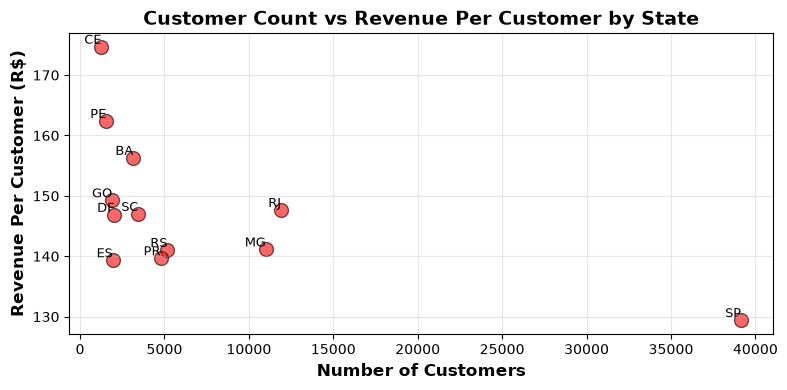

In [16]:

plt.figure(figsize=(8,4))

# Create scatter plot
plt.scatter(comparison['customer_unique_id'], 
            comparison['Revenue_Per_Customer'],
            s=100, alpha=0.6, color='red', edgecolor='black')

# Add state labels to each point
for idx, row in comparison.iterrows():
    plt.text(row['customer_unique_id'], 
             row['Revenue_Per_Customer'],
             idx,  # This is the state name
             fontsize=9, ha='right', va='bottom')

# Labels and title
plt.xlabel('Number of Customers', fontsize=12, fontweight='bold')
plt.ylabel('Revenue Per Customer (R$)', fontsize=12, fontweight='bold')
plt.title('Customer Count vs Revenue Per Customer by State', fontsize=14, fontweight='bold')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('customer count vs revenue per customer.png', dpi=300, bbox_inches='tight')
plt.show()

###  Geographical Revenue Analysis
São Paulo (SP) is the dominant market, contributing 38% of total revenue. Interestingly, while SP leads in volume, states like Bahia (BA) exhibit higher revenue per customer, suggesting a premium customer segment that warrants a differentiated marketing strategy.

# Product Analysis Section:

In [17]:
product=pd.read_csv("olist_products_dataset.csv")
product.sample(10)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
7359,966746deb2173a72d95ca8b80223f014,cama_mesa_banho,59.0,565.0,1.0,750.0,16.0,10.0,16.0
15595,84a5ff7347e4371b23168a1b69f2409d,papelaria,58.0,502.0,6.0,400.0,21.0,7.0,15.0
12746,b5aebb467d9a92162173cbd234e00d99,agro_industria_e_comercio,60.0,1843.0,3.0,550.0,16.0,16.0,16.0
5907,3c39f47a2595ed6989c1357d7926acd8,beleza_saude,52.0,191.0,3.0,50.0,19.0,11.0,23.0
12539,4c7288d0bf8ea00b7e9de295598d13a5,beleza_saude,48.0,648.0,4.0,2950.0,18.0,26.0,28.0
2963,e7d5464b94c9a5963f7c686fc80145ad,relogios_presentes,42.0,938.0,5.0,275.0,16.0,14.0,14.0
22018,e3323b0d3f79bdf85b58561d2218bc12,informatica_acessorios,57.0,764.0,1.0,167.0,21.0,10.0,12.0
12184,805e46e794f114d8800f55296251f907,fashion_calcados,53.0,408.0,5.0,1400.0,22.0,12.0,33.0
27875,4c42f0c72caf632a20df25562451c1a8,casa_construcao,56.0,1504.0,2.0,1160.0,26.0,18.0,19.0
26223,96ce4ff64224301c9da1dd92fa9551fa,utilidades_domesticas,58.0,1249.0,1.0,19050.0,43.0,79.0,41.0


In [18]:
translation=pd.read_csv("product_category_name_translation.csv")
translation.sample(10)

,product_category_name,product_category_name_english
44,industria_comercio_e_negocios,industry_commerce_and_business
15,telefonia_fixa,fixed_telephony
58,bebidas,drinks
12,papelaria,stationery
57,livros_importados,books_imported
49,construcao_ferramentas_seguranca,construction_tools_safety
50,fashion_underwear_e_moda_praia,fashion_underwear_beach
28,fashion_roupa_masculina,fashion_male_clothing
67,artes_e_artesanato,arts_and_craftmanship
62,casa_conforto_2,home_comfort_2


For better understanding merge english translation 

In [19]:
df3 = product.merge(translation, on='product_category_name', how='left')
df3.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,housewares


In [20]:
df4 = df2.merge(df3, on='product_id', how='left')
df4.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,...,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,...,21.88,moveis_escritorio,41.0,1141.0,1.0,8683.0,54.0,64.0,31.0,office_furniture
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,delivered,2018-01-12 20:48:24,2018-01-12 20:58:32,2018-01-15 17:14:59,...,46.48,utilidades_domesticas,43.0,1002.0,3.0,10150.0,89.0,15.0,40.0,housewares
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,2018-05-19 16:07:45,2018-05-20 16:19:10,2018-06-11 14:31:00,...,17.79,moveis_escritorio,55.0,955.0,1.0,8267.0,52.0,52.0,17.0,office_furniture
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,2018-03-13 16:06:38,2018-03-13 17:29:19,2018-03-27 23:22:42,...,23.36,moveis_escritorio,48.0,1066.0,1.0,12160.0,56.0,51.0,28.0,office_furniture
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,2018-07-29 09:51:30,2018-07-29 10:10:09,2018-07-30 15:16:00,...,22.25,casa_conforto,61.0,407.0,1.0,5200.0,45.0,15.0,35.0,home_confort


In [21]:
orders_product = (
    df4.groupby(['customer_state', 'product_category_name_english'])
       .agg(
           order_count=('order_id', 'nunique'),
           total_revenue=('price', 'sum')
       )
       .reset_index()
)

#  For EACH state, get top 3 categories
top_categories_per_state = (
    orders_product
    .sort_values('total_revenue', ascending=False)  # Sort by revenue
    .groupby('customer_state')                       # Group by state
    .head(3)                                         # Take top 3 from each group
)

top_categories_per_state.reset_index(drop=True, inplace=True)
top_categories_per_state

,customer_state,product_category_name_english,order_count,total_revenue
0,SP,bed_bath_table,4347,472238.07
1,SP,health_beauty,3715,453916.48
2,SP,watches_gifts,2090,421546.60
3,RJ,watches_gifts,789,174895.01
4,MG,health_beauty,990,154324.15
...,...,...,...,...
76,AC,watches_gifts,4,1389.60
77,AC,health_beauty,6,1386.58
78,RR,sports_leisure,6,1350.60
79,RR,home_appliances,3,954.18


In [32]:
# sorting the companies 
state_order = ['SP', 'RJ', 'MG', 'RS', 'PR', 'BA', 'SC', 'DF', 'GO', 'ES']

# Convert customer_state to categorical with this order
top_categories_per_state['customer_state'] = pd.Categorical(
    top_categories_per_state['customer_state'],
    categories=state_order,
    ordered=True
)

# Now sort by this order
top_categories_sorted = top_categories_per_state.sort_values('customer_state')
top_categories_sorted.reset_index(drop=True, inplace=True)
top_categories_per_state = top_categories_per_state[top_categories_per_state['customer_state'].isin(state_order)].copy()
top_categories_sorted

,customer_state,product_category_name_english,order_count,total_revenue
0,SP,bed_bath_table,4347,472238.07
1,SP,health_beauty,3715,453916.48
2,SP,watches_gifts,2090,421546.60
3,RJ,watches_gifts,789,174895.01
4,RJ,bed_bath_table,1357,144251.79
5,RJ,health_beauty,939,140236.35
6,MG,health_beauty,990,154324.15
7,MG,bed_bath_table,1120,128760.49
8,MG,watches_gifts,601,121622.03
9,RS,furniture_decor,438,53774.90


VISUALIZATION 

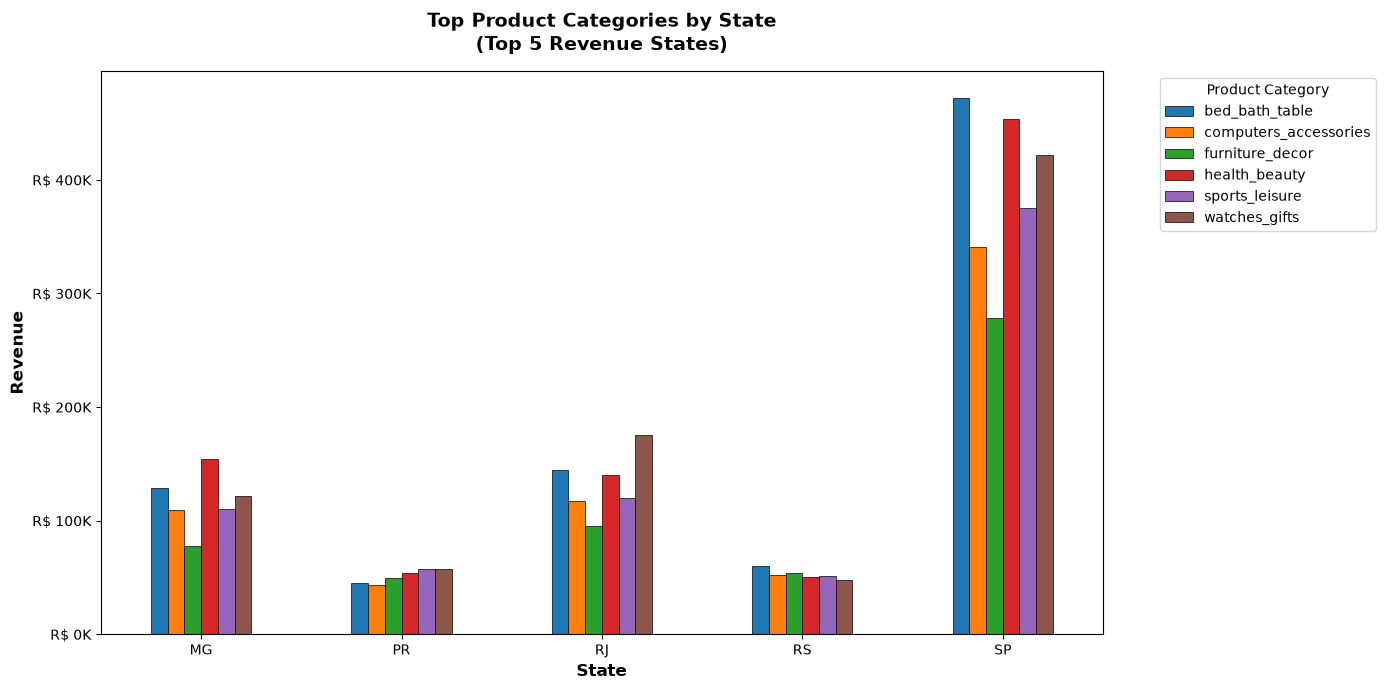

In [23]:
import matplotlib.pyplot as plt

# Step 1: Filter top 5 states
top_5_states = ['SP', 'RJ', 'MG', 'RS', 'PR']
top_cats = top_categories_sorted[top_categories_sorted['customer_state'].isin(top_5_states)]['product_category_name_english'].unique()
chart1_data = orders_product[orders_product['customer_state'].isin(top_5_states)
                             & orders_product['product_category_name_english'].isin(top_cats)]

# Step 2: Convert LONG to WIDE format using pivot_table
chart1_pivot = chart1_data.pivot_table(
    index='customer_state',      # Rows = States
    columns='product_category_name_english',  # Columns = Categories
    values='total_revenue',      # Values = Revenue
    aggfunc='sum'
).fillna(0)


# Step 3: Plot grouped bar chart
fig, ax = plt.subplots(figsize=(14, 7))
chart1_pivot.plot(kind='bar', ax=ax, edgecolor='black', linewidth=0.5)

# Step 4: Formatting
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, p: f'R$ {x/1000:.0f}K')
)
plt.title('Top Product Categories by State\n(Top 5 Revenue States)', 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('State', fontsize=12, fontweight='bold')
plt.ylabel('Revenue', fontsize=12, fontweight='bold')
plt.xticks(rotation=0)
plt.legend(title='Product Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('product_categories_by_state.png', dpi=300, bbox_inches='tight')
plt.show()

To check in BA vs SP per customer expense does product play any role 

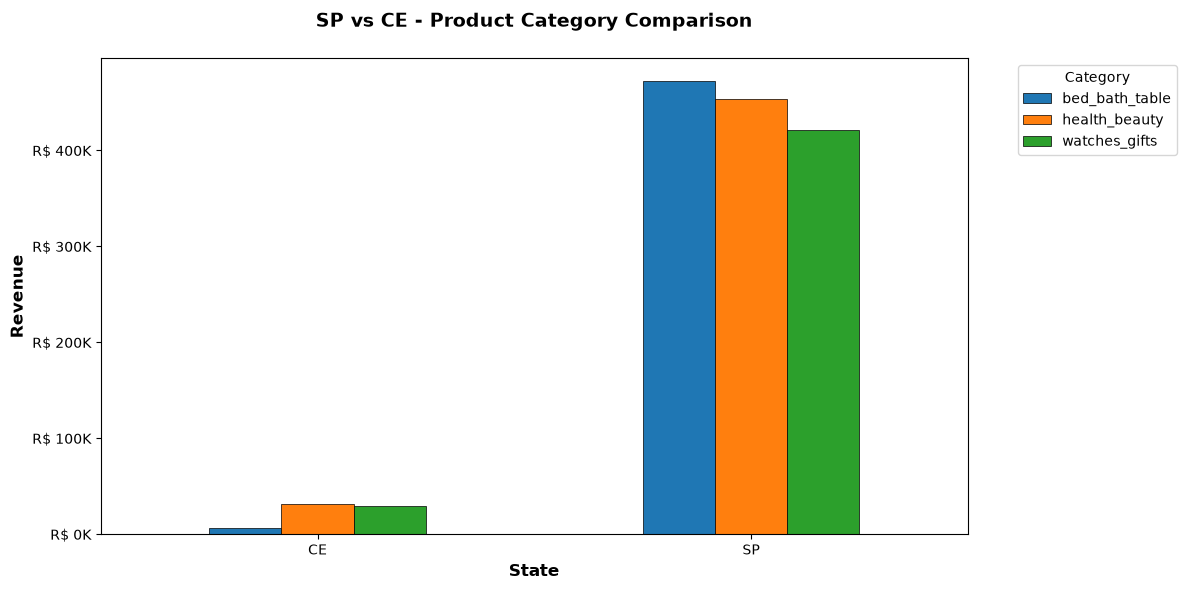

In [34]:
# Step 1: Filter only SP and CE
top_cats = top_categories_sorted[top_categories_sorted['customer_state'].isin(['SP', 'CE'])]['product_category_name_english'].unique()
compare_data = orders_product[orders_product['customer_state'].isin(['SP', 'CE'])
                              & orders_product['product_category_name_english'].isin(top_cats)]

# Step 2: Pivot
compare_pivot = compare_data.pivot_table(
    index='customer_state',
    columns='product_category_name_english',
    values='total_revenue',
    aggfunc='sum'
).fillna(0)

# Step 3: Plot
fig, ax = plt.subplots(figsize=(12, 6))
compare_pivot.plot(kind='bar', ax=ax, edgecolor='black', linewidth=0.5)

# Step 4: Formatting
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, p: f'R$ {x/1000:.0f}K')
)
plt.title('SP vs CE - Product Category Comparison\n', 
          fontsize=14, fontweight='bold')
plt.xlabel('State', fontsize=12, fontweight='bold')
plt.ylabel('Revenue', fontsize=12, fontweight='bold')
plt.xticks(rotation=0)
plt.legend(title='Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('sp_vs_ce_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

###  Product Category Preferences
The analysis of product categories reveals that bed_bath_table, health_beauty, and watches_gifts are the core revenue drivers across the board. The consistency of these top-performing categories indicates a same 3 categories lead in the biggest states across Brazil.

# Time Analysis Section

In [25]:
# Filter delivered orders
order_delivered = order[order['order_status'] == 'delivered'].copy()

# Convert timestamp (store back in dataframe)
order_delivered['order_purchase_timestamp'] = pd.to_datetime(
    order_delivered['order_purchase_timestamp']
)

# Extract month and year from purchase timestamp
order_delivered['month'] = order_delivered['order_purchase_timestamp'].dt.month
order_delivered['year'] = order_delivered['order_purchase_timestamp'].dt.year
order_delivered.sample(20)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,month,year
90959,7a4380b2d852be9f98a57d31d6a9c51b,837343b368cfbcf883cb6968069b5b2b,delivered,2017-06-29 11:52:18,2017-07-01 04:45:30,2017-07-03 13:27:00,2017-07-12 17:32:36,2017-07-25 00:00:00,6,2017
82724,780bb1875afb8783be7fab39382d8eee,15ce8ebbf78bb839bce4f80906c8727f,delivered,2017-07-19 10:37:51,2017-07-20 02:10:19,2017-07-21 19:51:59,2017-07-24 22:23:06,2017-08-01 00:00:00,7,2017
26023,9e4243313a1d4a651bb23ffa6edd96e2,4ca401a8fcf817e3bbee5408eb4b2e9e,delivered,2018-07-30 22:44:52,2018-08-01 03:32:21,2018-08-23 07:12:00,2018-08-28 19:20:56,2018-08-31 00:00:00,7,2018
13927,2c293bd3c9f41735731112a36cbcaf81,b42845800e932aa00790fd8ef2bcfa57,delivered,2017-10-14 13:22:39,2017-10-14 13:49:26,2017-10-17 17:19:48,2017-10-23 20:27:44,2017-11-08 00:00:00,10,2017
75998,1affa2b54c26489a1600dea208b13bfd,16ad0e153b12087b00ff6bba67fc0bac,delivered,2017-11-24 12:23:11,2017-11-24 14:32:24,2017-11-30 20:42:16,2018-01-05 00:41:43,2018-01-12 00:00:00,11,2017
4457,995cb1fde464cb3683cf2902d8827a13,985b35e7309802e954547d2f6fdfe9e9,delivered,2018-07-15 21:00:44,2018-07-15 21:15:19,2018-07-16 15:29:00,2018-07-25 21:41:16,2018-08-02 00:00:00,7,2018
12328,fd3634dbb2f578420b7b7dc1633766ce,2b02213d249d2abc717cc1c6bb4e9cb0,delivered,2017-06-30 14:03:15,2017-06-30 14:15:12,2017-07-03 14:32:37,2017-07-19 18:27:22,2017-07-28 00:00:00,6,2017
71002,0ed4f86f537498adc199e28f682e2946,7ccae4c14b25c44cc60e1d0d6e1268dd,delivered,2018-03-24 15:38:20,2018-03-24 15:50:25,2018-03-26 21:38:46,2018-04-03 00:14:22,2018-04-12 00:00:00,3,2018
81447,957e60e8b06f5c61044ad86aa626cd49,d1fdd448f8dccdf1fd1eef2008573b42,delivered,2017-11-27 23:35:57,2017-11-27 23:49:47,2017-12-04 17:58:06,2018-01-27 15:12:18,2017-12-28 00:00:00,11,2017
84895,cc16ebef1f3a4045ed7084406d057749,c2dd4419fff3be4ee48f93165e30984b,delivered,2018-05-21 00:55:44,2018-05-21 01:10:23,2018-05-21 10:21:00,2018-06-07 21:47:29,2018-06-12 00:00:00,5,2018


In [26]:
df5=order_delivered.merge(order_items, on='order_id', how='inner')   
df5.sample(20)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,month,year,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
12521,36307ab4d5c4b59fbc4034d2adb2cb77,27ed9299eff7fddbfdd20337369ccfc8,delivered,2018-05-10 11:05:59,2018-05-10 11:36:17,2018-05-10 15:18:00,2018-05-15 13:20:50,2018-05-29 00:00:00,5,2018,1,df581a0b9a4bf71da645a0a3d5d2b4fe,c013e57c075a06e5b5c48ee03c525719,2018-05-16 11:31:58,32.99,13.71
58236,fb20235870d6172778522e8fb798f27c,9bb41b35087bdd06d3fcf23b63f7dc86,delivered,2017-12-05 19:04:41,2017-12-05 19:30:24,2017-12-07 05:37:07,2017-12-11 18:42:25,2018-01-10 00:00:00,12,2017,2,305edcc7b46afd87ca6979ed0409fb09,0b90b6df587eb83608a64ea8b390cf07,2017-12-19 19:30:24,189.40,13.46
37595,d0b00b87c4e240a8c84a2cf01548439f,3723c0426e228af1f40c3a81174547db,delivered,2018-02-10 18:28:45,2018-02-10 18:48:19,2018-02-17 03:58:57,2018-02-22 16:29:03,2018-03-06 00:00:00,2,2018,1,8562e2c780a345b609e1b802d7e3e4ae,8160255418d5aaa7dbdc9f4c64ebda44,2018-02-15 18:48:19,79.90,12.90
39041,0625530241d6fc5812c0062962c29a7e,5a5ff214d077aa3eb285242ed7e36c4d,delivered,2018-06-24 18:35:49,2018-06-24 18:55:46,2018-06-26 09:28:00,2018-07-03 19:25:49,2018-07-24 00:00:00,6,2018,1,6f3b5b605d91b7439c5e3f5a8dffeea7,4869f7a5dfa277a7dca6462dcf3b52b2,2018-06-27 18:55:46,148.00,19.14
12091,14bc69ea319de2d00a2d781ecf29df42,a92bd6e7f927b779c75918e540747576,delivered,2017-03-03 08:22:03,2017-03-03 08:30:18,2017-03-03 10:46:58,2017-03-13 09:37:55,2017-04-05 00:00:00,3,2017,1,6d6b0f6705c1acf1128ecf19d57d5444,891071be6ba827b591264c90c2ae8a63,2017-03-09 08:30:18,25.00,14.52
100745,060c88a63c83f2dfaeea611cc18edefd,6a0635195b073ff200c9900416b8a99f,delivered,2018-07-09 14:59:01,2018-07-09 15:15:09,2018-07-10 08:33:00,2018-07-20 16:51:35,2018-07-27 00:00:00,7,2018,1,3168b2696b15ca440b92afa9e011a084,5cf13accae3222c70a9cac40818ae839,2018-07-11 15:15:09,109.90,51.06
88362,0345ba423eed2b009e0e407b19c422e4,9418fa1d37504cf6f7dafc0420acf406,delivered,2017-05-15 12:55:13,2017-05-15 13:10:13,2017-05-16 12:29:04,2017-05-22 10:29:39,2017-06-13 00:00:00,5,2017,1,2e7980421ad7946eab8a71b637955704,8e6cc767478edae941d9bd9eb778d77a,2017-05-23 13:10:13,60.08,17.67
31924,b226cacb0f9d03a94be963d2d8ceff65,3fd923429a0a3f921b44ae5e4dc2c96f,delivered,2018-06-04 07:25:50,2018-06-04 07:51:21,2018-06-04 14:29:00,2018-06-11 20:46:20,2018-07-24 00:00:00,6,2018,1,5c92f9ec6027c92a5293a46e9175e817,6a8a889bde935bafa76d7848782dfaf9,2018-06-12 07:51:21,25.49,15.23
44280,dc20804f9d8ea2452990f7c41ccb34bc,57feb621213d35470d052e8c25b27e2c,delivered,2018-04-23 12:05:10,2018-04-24 19:07:37,2018-04-24 17:45:38,2018-04-27 19:33:10,2018-05-11 00:00:00,4,2018,1,0a4093a4af429dc0a9334300e5c13ae5,da8622b14eb17ae2831f4ac5b9dab84a,2018-04-30 03:31:59,29.90,7.71
52764,894688f5124158773f73df86a3b83c6f,22b6b404010c1f6864e347b5202085a6,delivered,2017-10-24 23:18:35,2017-10-24 23:28:15,2017-10-27 19:04:00,2017-11-01 22:10:47,2017-11-17 00:00:00,10,2017,2,b532349fe46b38fbc7bb3914c1bdae07,1025f0e2d44d7041d6cf58b6550e0bfa,2017-10-31 23:28:15,38.40,16.11


In [27]:
monthly_revenue = (
    df5.groupby(["year", "month"], as_index=False)
       .agg(total_revenue=("price", "sum"))
       .sort_values(["year", "month"])
)

monthly_revenue


,year,month,total_revenue
0,2016,9,134.97
1,2016,10,40325.11
2,2016,12,10.90
3,2017,1,111798.36
4,2017,2,234223.40
5,2017,3,359198.85
6,2017,4,340669.68
7,2017,5,489338.25
8,2017,6,421923.37
9,2017,7,481604.52


In [28]:
annual_revenue=(
    df5.groupby(['year'] , as_index=False)
    .agg(total_revenue=("price", "sum"))
    .sort_values(by='year')
)

annual_revenue

,year,total_revenue
0,2016,40470.98
1,2017,5962902.01
2,2018,7218125.12


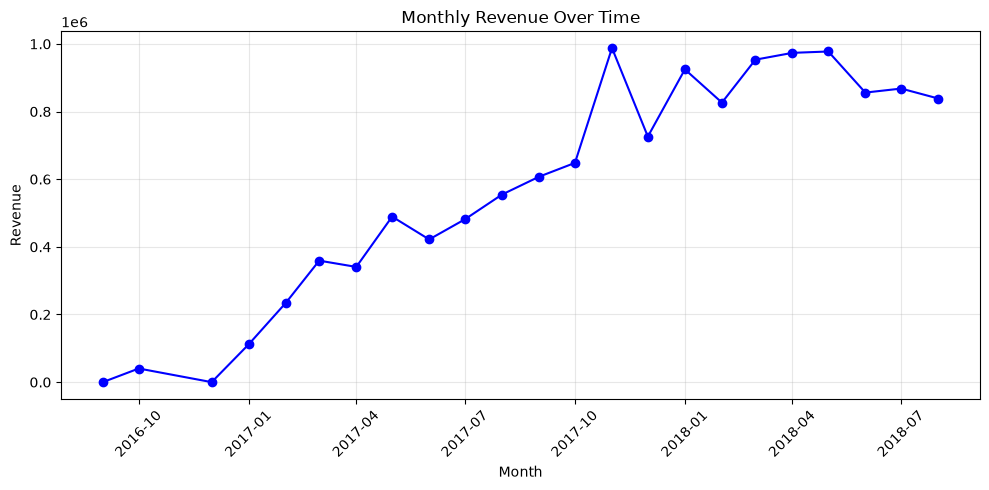

In [29]:
# Create a temporary dataframe
df_plot = monthly_revenue.copy()
# Convert year and month to string first
df_plot['date'] = df_plot['year'].astype(str) + '-' + df_plot['month'].astype(str)

# 2. Convert that string to a real datetime object
df_plot['date'] = pd.to_datetime(df_plot['date'])

plt.plot(df_plot['date'], df_plot['total_revenue'],
         marker='o', color='b', label='Monthly Revenue')
plt.title('Monthly Revenue Over Time')
plt.gcf().set_size_inches(10, 5)
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('monthly_revenue_over_time.png', dpi=300, bbox_inches='tight')
plt.show()

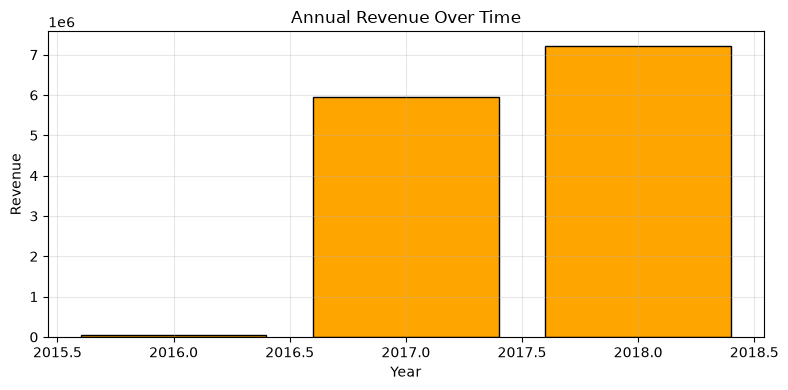

In [31]:
plt.bar(annual_revenue['year'], annual_revenue['total_revenue'], color='orange', edgecolor='black')
plt.title('Annual Revenue Over Time')
plt.gcf().set_size_inches(8, 4)
plt.xlabel('Year')
plt.ylabel('Revenue')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('annual_revenue_2016_sep-dec_2018_jan-aug.png', dpi=300, bbox_inches='tight')
plt.show()


### Temporal Revenue Trends
The analysis of annual and monthly revenue trends indicates strong positive growth from 2016 through 2018. Month-over-month analysis shows significant revenue spikes, suggesting strong seasonal purchasing patterns. This trend data is vital for inventory planning and optimizing marketing spend during peak sales periods.

# Payment Analysis Section:

In [ ]:
payment = pd.read_csv("olist_order_payments_dataset.csv")
payment.head(20)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45
5,298fcdf1f73eb413e4d26d01b25bc1cd,1,credit_card,2,96.12
6,771ee386b001f06208a7419e4fc1bbd7,1,credit_card,1,81.16
7,3d7239c394a212faae122962df514ac7,1,credit_card,3,51.84
8,1f78449c87a54faf9e96e88ba1491fa9,1,credit_card,6,341.09
9,0573b5e23cbd798006520e1d5b4c6714,1,boleto,1,51.95


In [ ]:
payment_analysis = payment.groupby('payment_type').agg(
    total_revenue=('payment_value', 'sum'),
    order_count=('order_id', 'nunique')
).sort_values(by='total_revenue', ascending=False).reset_index()
payment_analysis

,payment_type,total_revenue,order_count
0,credit_card,12542084.19,76505
1,boleto,2869361.27,19784
2,voucher,379436.87,3866
3,debit_card,217989.79,1528
4,not_defined,0.00,3


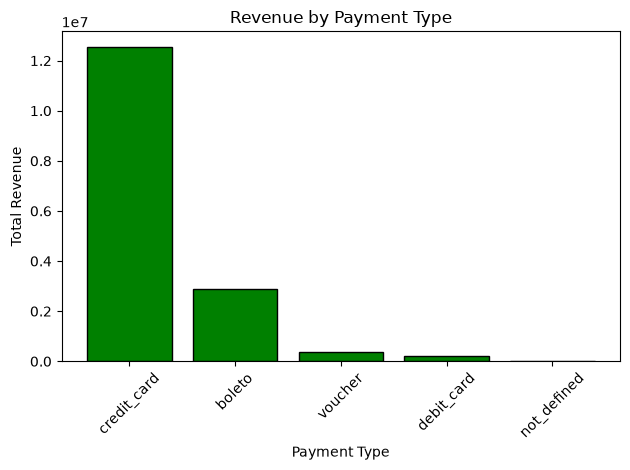

In [ ]:
plt.bar(payment_analysis['payment_type'], payment_analysis['total_revenue'], color='green', edgecolor='black')
plt.title('Revenue by Payment Type')
plt.xlabel('Payment Type')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('revenue_by_payment_type.png', dpi=300, bbox_inches='tight')
plt.show()

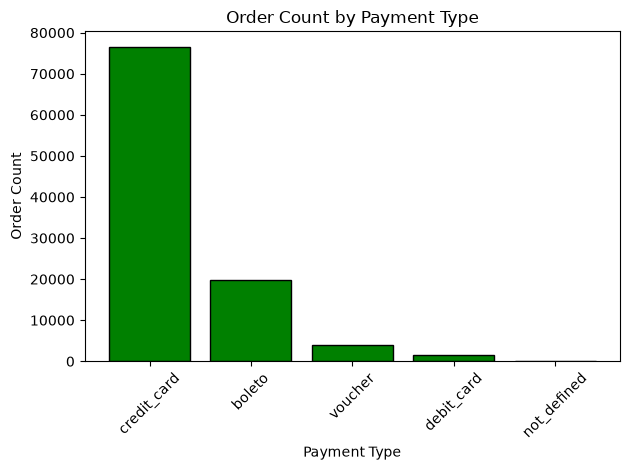

In [ ]:
plt.bar(payment_analysis['payment_type'], payment_analysis['order_count'], color='green', edgecolor='black')
plt.title('Order Count by Payment Type')
plt.xlabel('Payment Type')
plt.ylabel('Order Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('order_count_by_payment_type.png', dpi=300, bbox_inches='tight')
plt.show()

###  Payment Method Insights
Credit cards are the primary payment method for the vast majority of transactions. This insight suggests that the company’s operational focus should be on ensuring high-availability and security for credit card processing, as any disruption here would disproportionately impact revenue.

# Delivery Analysis Section :

In [ ]:
review = pd.read_csv("olist_order_reviews_dataset.csv")
review = review.sort_values('review_answer_timestamp').drop_duplicates('order_id', keep='last')

In [ ]:
delivery=order_delivered.merge(review, on='order_id', how='inner')
delivery.reset_index(drop=True, inplace=True)
delivery

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,month,year,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,10,2017,a54f0611adc9ed256b57ede6b6eb5114,4,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,7,2018,8d5266042046a06655c8db133d120ba5,4,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00,2018-08-08 18:37:50
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,8,2018,e73b67b67587f7644d5bd1a52deb1b01,5,NaN,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,11,2017,359d03e676b3c069f62cadba8dd3f6e8,5,NaN,O produto foi exatamente o que eu esperava e e...,2017-12-03 00:00:00,2017-12-05 19:21:58
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,2,2018,e50934924e227544ba8246aeb3770dd4,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 13:02:51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95827,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00,3,2017,e262b3f92d1ce917aa412a9406cf61a6,5,NaN,NaN,2017-03-22 00:00:00,2017-03-23 11:02:08
95828,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00,2,2018,29bb71b2760d0f876dfa178a76bc4734,4,NaN,So uma peça que veio rachado mas tudo bem rs,2018-03-01 00:00:00,2018-03-02 17:50:01
95829,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00,8,2017,371579771219f6db2d830d50805977bb,5,NaN,Foi entregue antes do prazo.,2017-09-22 00:00:00,2017-09-22 23:10:57
95830,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,1,2018,8ab6855b9fe9b812cd03a480a25058a1,2,NaN,Foi entregue somente 1. Quero saber do outro p...,2018-01-26 00:00:00,2018-01-27 09:16:56


In [ ]:
delivery['order_delivered_customer_date'] = pd.to_datetime(delivery['order_delivered_customer_date'])
delivery['order_estimated_delivery_date'] = pd.to_datetime(delivery['order_estimated_delivery_date'])
delivery = delivery.dropna(subset=['order_delivered_customer_date'])
delivery.info()

<class 'pandas.DataFrame'>
Index: 95824 entries, 0 to 95831
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       95824 non-null  str           
 1   customer_id                    95824 non-null  str           
 2   order_status                   95824 non-null  str           
 3   order_purchase_timestamp       95824 non-null  datetime64[us]
 4   order_approved_at              95810 non-null  str           
 5   order_delivered_carrier_date   95823 non-null  str           
 6   order_delivered_customer_date  95824 non-null  datetime64[us]
 7   order_estimated_delivery_date  95824 non-null  datetime64[us]
 8   month                          95824 non-null  int32         
 9   year                           95824 non-null  int32         
 10  review_id                      95824 non-null  str           
 11  review_score                   

In [ ]:
delivery['is_late'] = delivery['order_delivered_customer_date'] - delivery['order_estimated_delivery_date']
# we only fletch out days so we can analyze the delay in days
delivery['delay_days'] = delivery['is_late'].dt.total_seconds() / 86400
# convert days into a categorical variable for better visualization
delivery['is_late'] = delivery['delay_days'].apply(lambda x: 'Late' if x > 0 else 'On Time')

In [ ]:
# Group by the 'is_late' flag and calculate the mean of 'review_score'
review_impact = delivery.groupby('is_late')['review_score'].mean()
print(review_impact)

is_late
Late       2.565070
On Time    4.294114
Name: review_score, dtype: float64


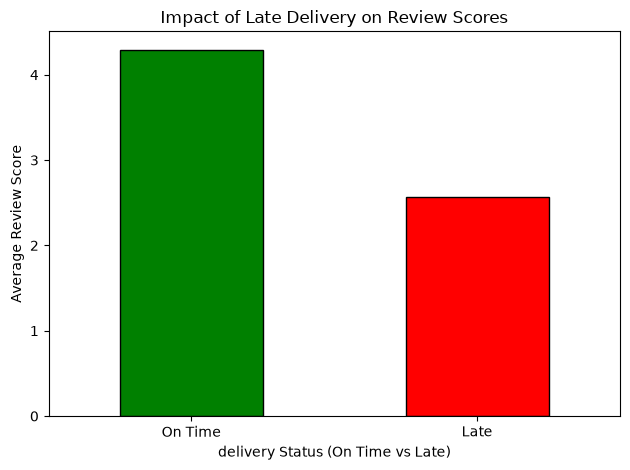

In [ ]:
# Simple plot of review_impact
review_impact = review_impact.reindex(['On Time', 'Late'])
review_impact.plot(kind='bar', color=['green', 'red'], edgecolor='black')
plt.title('Impact of Late Delivery on Review Scores')
plt.xlabel('delivery Status (On Time vs Late)')
plt.ylabel('Average Review Score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('impact_of_late_delivery_on_review_scores.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Create bins for delay duration
bins = [-1000, 0, 3, 7, 14, 30, 1000]
labels = ['Early/On-Time', '0-3 Days', '3-7 Days', '7-14 Days', '14-30 Days', '30+ Days']

delivery['delay_category'] = pd.cut(delivery['delay_days'], bins=bins, labels=labels)

# Group by these new categories and get the average review score
delay_impact = delivery.groupby('delay_category')['review_score'].mean()
print(delay_impact)

delay_category
Early/On-Time    4.294114
0-3 Days         3.765933
3-7 Days         2.316413
7-14 Days        1.743135
14-30 Days       1.614987
30+ Days         2.026239
Name: review_score, dtype: float64


In [ ]:
print(delivery['delay_category'].value_counts())

delay_category
Early/On-Time    88163
0-3 Days          2636
3-7 Days          1773
7-14 Days         1748
14-30 Days        1161
30+ Days           343
Name: count, dtype: int64


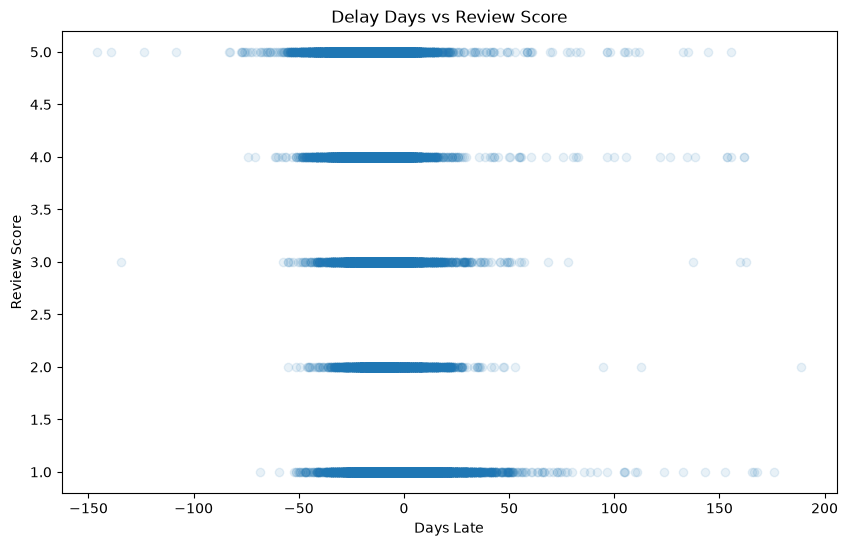

In [ ]:
plt.figure(figsize=(10,6))
plt.scatter(delivery['delay_days'], delivery['review_score'], alpha=0.1)
plt.title('Delay Days vs Review Score')
plt.xlabel('Days Late')
plt.ylabel('Review Score')
plt.savefig("DelayDays_vs_Review.png", dpi=300, bbox_inches='tight')
plt.show()

###  Operational Impact on Customer Satisfaction
This analysis is associated with between delivery performance and customer sentiment. Late deliveries result in a dramatic decrease in average review scores, dropping from 4.29 for on-time deliveries to 2.27 for late arrivals. This quantitative evidence highlights the critical need to optimize logistics to maintain customer loyalty.